In [1]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency, f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd


In [3]:
df = pd.read_csv("Titanic-Dataset.csv")
print(df.shape)


(891, 12)


In [4]:
alpha = 0.05
num_col, group_col = "Age", "Sex"
group_a, group_b = "male", "female"
cat_col1, cat_col2 = "Sex", "Survived"
anova_num_col, anova_group_col = "Fare", "Pclass"

def decide(p):
    return "Reject H0" if p < alpha else "Fail to reject H0"

print(df[group_col].value_counts())
print(df[anova_group_col].value_counts())


Sex
male      577
female    314
Name: count, dtype: int64
Pclass
3    491
1    216
2    184
Name: count, dtype: int64


453 30.72664459161148 14.678200823816601
261 27.915708812260537 14.110146457544129


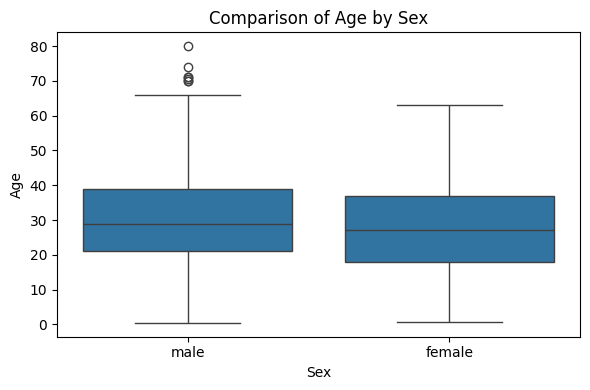

2.5258975171938896 0.011814913211889735 Reject H0


In [5]:
g1 = df.loc[df[group_col] == group_a, num_col].dropna()
g2 = df.loc[df[group_col] == group_b, num_col].dropna()
print(len(g1), g1.mean(), g1.std())
print(len(g2), g2.mean(), g2.std())

plt.figure(figsize=(6, 4))
sns.boxplot(data=df[df[group_col].isin([group_a, group_b])], x=group_col, y=num_col)
plt.title(f"Comparison of {num_col} by {group_col}")
plt.tight_layout()
plt.show()

t_stat, t_p = ttest_ind(g1, g2, equal_var=False)
print(t_stat, t_p, decide(t_p))


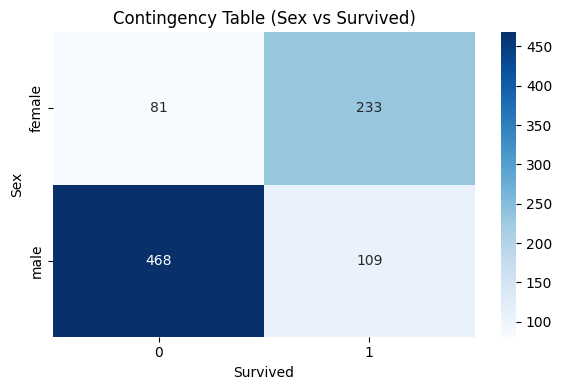

260.71702016732104 1 1.1973570627755645e-58 Reject H0
Survived       0       1
Sex                     
female    193.47  120.53
male      355.53  221.47


In [6]:
chi_df = df[[cat_col1, cat_col2]].dropna()
observed = pd.crosstab(chi_df[cat_col1], chi_df[cat_col2])

plt.figure(figsize=(6, 4))
sns.heatmap(observed, annot=True, fmt="d", cmap="Blues")
plt.title(f"Contingency Table ({cat_col1} vs {cat_col2})")
plt.tight_layout()
plt.show()

chi2, chi_p, dof, expected = chi2_contingency(observed)
print(chi2, dof, chi_p, decide(chi_p))

expected_df = pd.DataFrame(expected, index=observed.index, columns=observed.columns)
print(expected_df.round(2))


        count       mean
Pclass                  
1         216  84.154687
2         184  20.662183
3         491  13.675550


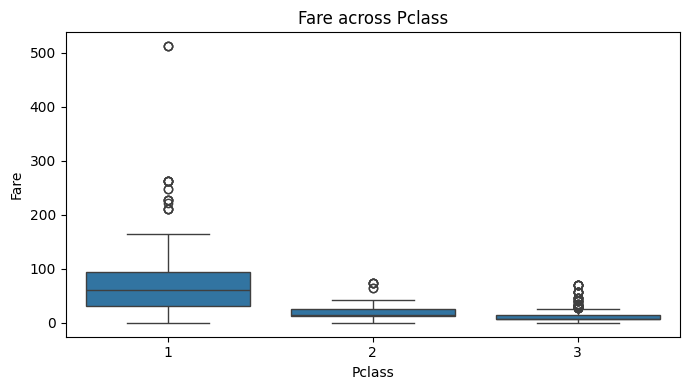

242.34415651744806 1.0313763209142051e-84 Reject H0


In [7]:
groups_used = df[anova_group_col].value_counts().head(3).index.tolist()
anova_df = df[df[anova_group_col].isin(groups_used)]
samples = [anova_df.loc[anova_df[anova_group_col] == g, anova_num_col].dropna() for g in groups_used]

print(anova_df.groupby(anova_group_col)[anova_num_col].agg(["count", "mean"]))

plt.figure(figsize=(7, 4))
sns.boxplot(data=anova_df, x=anova_group_col, y=anova_num_col)
plt.title(f"{anova_num_col} across {anova_group_col}")
plt.tight_layout()
plt.show()

f_stat, anova_p = f_oneway(*samples)
print(f_stat, anova_p, decide(anova_p))


In [8]:
clean_anova = anova_df[[anova_num_col, anova_group_col]].dropna()
tukey = pairwise_tukeyhsd(clean_anova[anova_num_col], clean_anova[anova_group_col], alpha=alpha)
print(tukey)


 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj  lower    upper   reject
-----------------------------------------------------
     1      2 -63.4925   0.0 -72.9165 -54.0685   True
     1      3 -70.4791   0.0 -78.1489 -62.8094   True
     2      3  -6.9866 0.108 -15.1064   1.1331  False
-----------------------------------------------------


In [9]:
results = pd.DataFrame({
    "Test": ["Welch's t-test", "Chi-square test", "One-way ANOVA"],
    "Statistic": [t_stat, chi2, f_stat],
    "p-value": [t_p, chi_p, anova_p]
})
results["Decision"] = results["p-value"].apply(decide)
print(results)
results.to_csv("hypothesis_testing_results.csv", index=False)


              Test   Statistic       p-value   Decision
0   Welch's t-test    2.525898  1.181491e-02  Reject H0
1  Chi-square test  260.717020  1.197357e-58  Reject H0
2    One-way ANOVA  242.344157  1.031376e-84  Reject H0
